# Day 11 — Data Visualization with Matplotlib and Seaborn

**Project:** Sales Data Visualization  
**Objective:** Create at least five meaningful charts using 100 sample sales records and write one business observation for each chart.

**Dataset:** `Day13_Sales_100_Records.csv`  
Keep this CSV in the same folder as this notebook.

> This is synthetic practice data. Interpretations describe this sample only and should not be treated as conclusions about a real company.

## 1. Import libraries and load data

Matplotlib creates charts; Seaborn makes statistical visualizations easier. Pandas prepares the data.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("Day13_Sales_100_Records.csv")
df["OrderDate"] = pd.to_datetime(df["OrderDate"], errors="coerce")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (100, 11)


,OrderID,OrderDate,Product,Category,Region,SalesChannel,CustomerSegment,Quantity,UnitPrice,DiscountPct,Sales
0,ORD001,2026-09-24,Headphones,Accessories,Mumbai,Online,Corporate,3,2700,0.00,8100.0
1,ORD002,2026-10-17,Keyboard,Accessories,Mumbai,Phone,Small Business,2,1100,0.15,1870.0
2,ORD003,2026-07-02,Laptop,Electronics,Nashik,Online,Individual,1,53000,0.15,45050.0
3,ORD004,2026-10-10,Headphones,Accessories,Nashik,Retail Store,Individual,7,3700,0.00,25900.0
4,ORD005,2026-09-24,Printer,Electronics,Nashik,Retail Store,Corporate,3,13500,0.10,36450.0


## 2. Check the data before charting

In [7]:
display(df.describe())

print("Missing values:")
display(df.isna().sum().to_frame("Missing Count"))

print("Exact duplicate rows:", df.duplicated().sum())

,OrderDate,Quantity,UnitPrice,DiscountPct,Sales
count,100,100.000000,100.000000,100.000000,100.00000
mean,2026-08-26 00:28:48,3.590000,13721.000000,0.063000,29548.25000
min,2026-07-01 00:00:00,1.000000,300.000000,0.000000,500.00000
25%,2026-07-20 18:00:00,2.000000,1100.000000,0.000000,3400.00000
50%,2026-08-26 12:00:00,3.000000,2700.000000,0.050000,12835.00000
75%,2026-09-25 00:00:00,5.000000,15250.000000,0.100000,32415.00000
max,2026-10-28 00:00:00,8.000000,62000.000000,0.150000,176700.00000
std,NaN,2.340228,19540.547303,0.058439,41105.48083


Missing values:


,Missing Count
OrderID,0
OrderDate,0
Product,0
Category,0
Region,0
SalesChannel,0
CustomerSegment,0
Quantity,0
UnitPrice,0
DiscountPct,0


Exact duplicate rows: 0


## Visualization 1 — Bar chart: Revenue by product

**Business question:** Which products generate the highest total sales?

**Interpretation prompt:** Identify the top product and compare it with the next product. Revenue does not equal profit because costs are not provided.

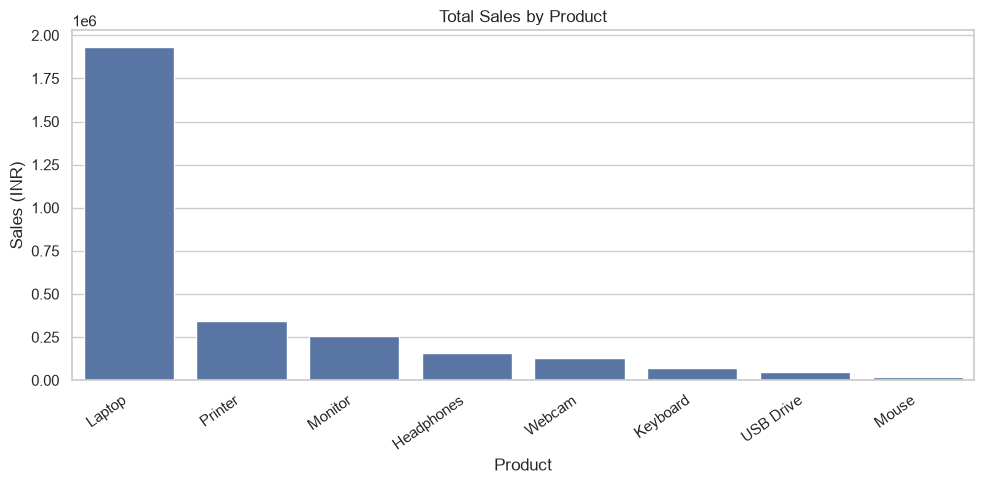

,Product,Sales
2,Laptop,1931235.0
5,Printer,341560.0
3,Monitor,257315.0
0,Headphones,159235.0
7,Webcam,130970.0
1,Keyboard,70010.0
6,USB Drive,46645.0
4,Mouse,17855.0


In [8]:
product_sales = df.groupby("Product", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=product_sales, x="Product", y="Sales")
plt.title("Total Sales by Product")
plt.xlabel("Product")
plt.ylabel("Sales (INR)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

display(product_sales)

**Write your business observation:** The product with the highest revenue is ______. Its total sales are ______. This tells us ______.

## Visualization 2 — Line chart: Monthly sales trend

**Business question:** How do total sales vary by month?

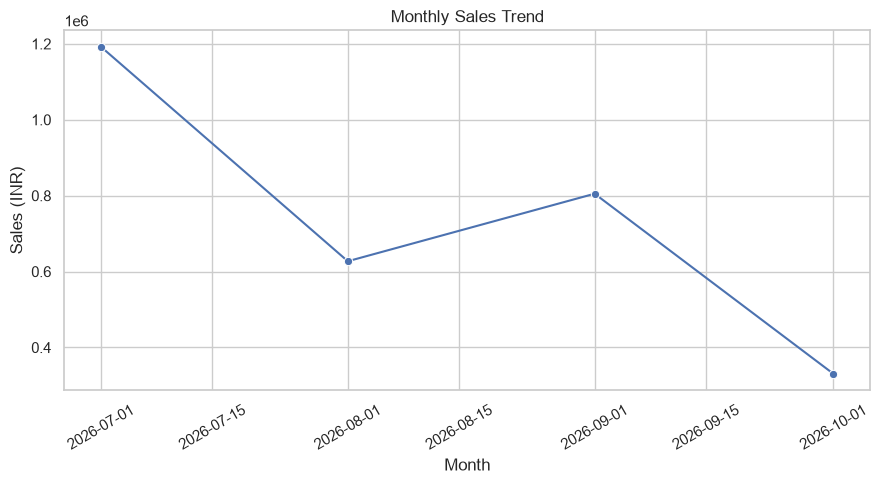

,OrderDate,Sales
0,2026-07-01,1192065.0
1,2026-08-01,627180.0
2,2026-09-01,805055.0
3,2026-10-01,330525.0


In [9]:
monthly_sales = (
    df.set_index("OrderDate")
      .resample("MS")["Sales"]
      .sum()
      .reset_index()
)

plt.figure(figsize=(9, 5))
sns.lineplot(data=monthly_sales, x="OrderDate", y="Sales", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (INR)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(monthly_sales)

**Write your business observation:** The month with the highest sales is ______. Sales from one month to the next ______. Only four months of synthetic data are available, so do not claim long-term seasonality.

## Visualization 3 — Histogram: Distribution of order sales

**Business question:** Are most orders low-value, mid-value, or high-value?

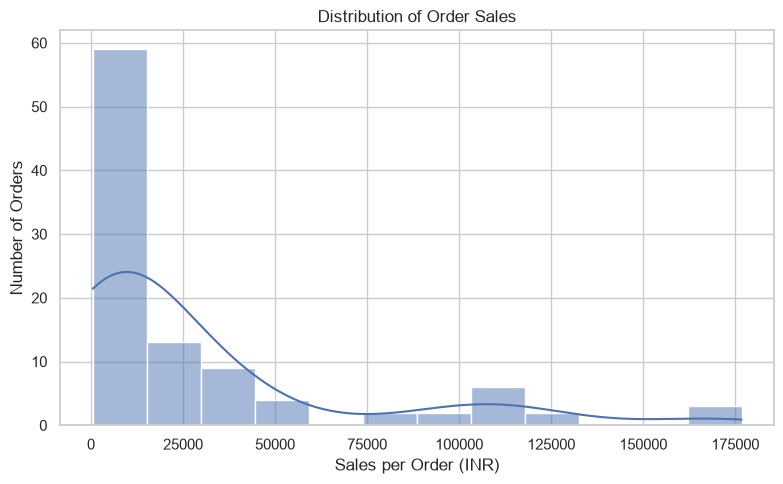

In [10]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Sales", bins=12, kde=True)
plt.title("Distribution of Order Sales")
plt.xlabel("Sales per Order (INR)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

**Write your business observation:** Most order values appear concentrated around ______. The distribution is ______ (roughly symmetric / right-skewed / left-skewed).

## Visualization 4 — Box plot: Sales by product

**Business question:** How spread out are order sales for different products, and are there potential outliers?

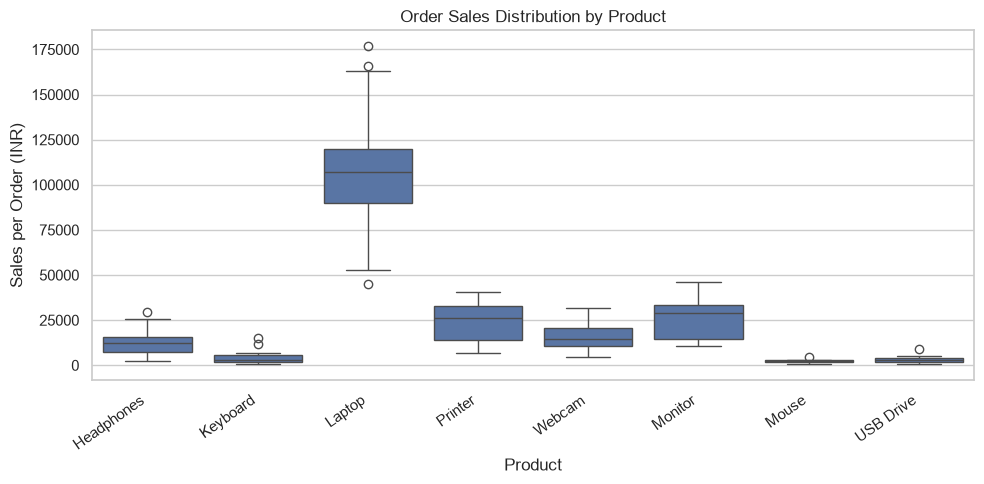

In [11]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Product", y="Sales")
plt.title("Order Sales Distribution by Product")
plt.xlabel("Product")
plt.ylabel("Sales per Order (INR)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

**Write your business observation:** The product with the widest spread in order sales is ______. A point beyond the whiskers is a potential outlier, not automatically an error; verify it with the source data.

## Visualization 5 — Scatter plot: Quantity vs sales

**Business question:** How are quantity and sales related in this dataset?

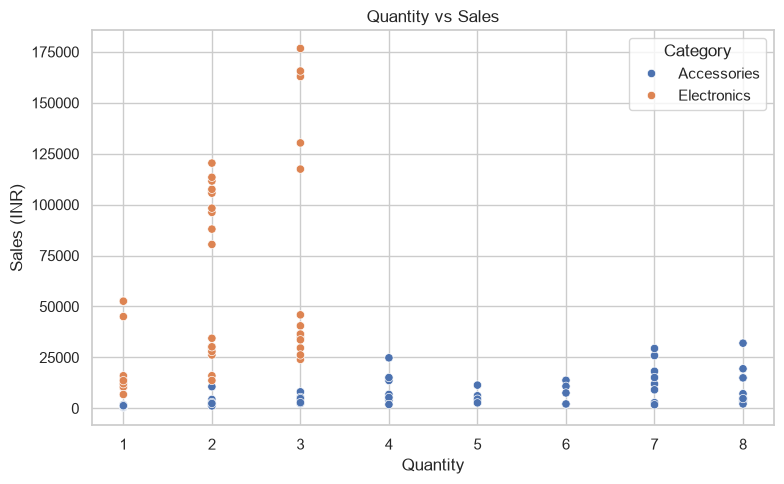

In [12]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Quantity", y="Sales", hue="Category")
plt.title("Quantity vs Sales")
plt.xlabel("Quantity")
plt.ylabel("Sales (INR)")
plt.tight_layout()
plt.show()

**Write your business observation:** The scatter plot shows ______ relationship between quantity and sales. Product prices differ, so quantity alone may not explain sales.

## Visualization 6 — Correlation heatmap

**Business question:** Which numeric variables move together in a linear way?

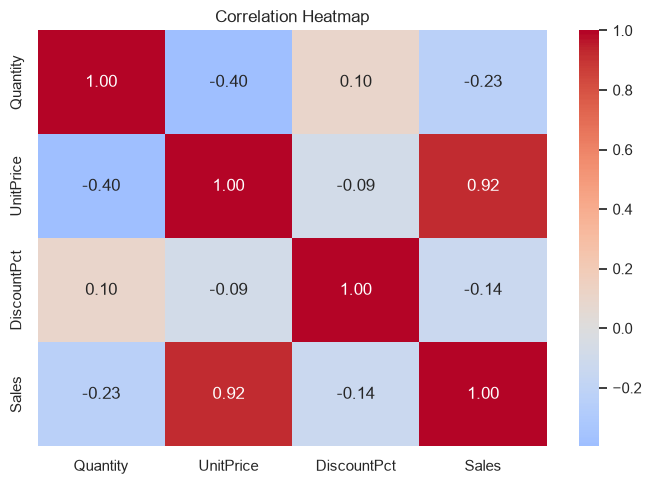

,Quantity,UnitPrice,DiscountPct,Sales
Quantity,1.000000,-0.397163,0.098454,-0.233996
UnitPrice,-0.397163,1.000000,-0.085733,0.920181
DiscountPct,0.098454,-0.085733,1.000000,-0.138758
Sales,-0.233996,0.920181,-0.138758,1.000000


In [13]:
numeric_cols = ["Quantity", "UnitPrice", "DiscountPct", "Sales"]
corr = df[numeric_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

display(corr)

**Write your business observation:** The strongest positive numeric correlation in this matrix is between ______ and ______. Correlation does not prove causation, and mixed product prices can affect relationships.

## 3. Summary of visualizations

Fill in the table after running each chart.

In [14]:
visualization_summary = pd.DataFrame({
    "Chart": [
        "Bar chart — Sales by product",
        "Line chart — Monthly sales",
        "Histogram — Order sales distribution",
        "Box plot — Sales by product",
        "Scatter plot — Quantity vs sales",
        "Heatmap — Numeric correlations"
    ],
    "Business question": [
        "Which products generate the most revenue?",
        "How do sales vary by month?",
        "What is the distribution of order values?",
        "How does sales spread vary by product?",
        "How are quantity and sales related?",
        "Which numeric variables are correlated?"
    ],
    "Business observation": ["Write after reviewing chart"] * 6
})
display(visualization_summary)

,Chart,Business question,Business observation
0,Bar chart — Sales by product,Which products generate the most revenue?,Write after reviewing chart
1,Line chart — Monthly sales,How do sales vary by month?,Write after reviewing chart
2,Histogram — Order sales distribution,What is the distribution of order values?,Write after reviewing chart
3,Box plot — Sales by product,How does sales spread vary by product?,Write after reviewing chart
4,Scatter plot — Quantity vs sales,How are quantity and sales related?,Write after reviewing chart
5,Heatmap — Numeric correlations,Which numeric variables are correlated?,Write after reviewing chart


## 4. Limitations

- The dataset is synthetic and contains only 100 records.
- It covers a limited period (July–October 2026).
- Cost, profit, returns, and customer identifiers are not available.
- Correlation does not establish cause and effect.
- Potential outliers require business context before any records are changed.

## 5. Conclusion

Write 3–5 sentences describing the main patterns, a cautious business recommendation, and the limitations of this analysis.